# PSA_CalcFADC: 波形の積分(hg, lg)と温度

`PSA_ReadData` が読んだ波形から、ヒットごとの信号の大きさを求めます。`psa_decode.py` の `decode_events` と同じ計算です。

1 ch(1 ブロック)の MPPC の信号は、抵抗分割で 4 隅の信号に分けられ、それぞれ High Gain(HG)と Low Gain(LG)で読まれます。
1 ヒットは **8 本(HG0〜3、LG0〜3)× 50 サンプル**の波形です。

| 手順 | 中身 | パラメータ |
|---|---|---|
| 1. ペデスタル | 8 本それぞれ、最初の 23 サンプルの平均を引く | `pedestal_samples` |
| 2. ピーク | ペデスタルを引いた LG の 4 本の和が一番大きいサンプル(`peak_id`) | |
| 3. 積分 | 8 本それぞれ、ピークの 4 サンプル前から 9 サンプル後までを台形積分(`wave_sum[8]`) | `window_front`, `window_back`(`fixed_window: true` なら `fixed_start`〜`fixed_stop`) |
| 4. hg, lg | `hg` = HG の 4 本の積分の和、`lg` = LG の 4 本の和 [ADC × サンプル] | |
| 5. 飽和 | どこかのサンプルが 16383 なら `satu_h`(HG)、`satu_l`(LG) | |
| 6. 温度 | 温度センサー 6 個: T = (生の値 − b) / a [°C]。a, b は `psa_param_file` の `HA` 列が `ha<NN>` の行 | `psa_param_file` |

台形積分は、窓の始まり ws から終わり we まで $\sum_{r=ws+1}^{we} (w_{r-1} + w_r)/2$ です(サンプルの間隔を 1 とする)。

温度センサーの並び(TL, TR, ML, MR, BL, BR)は、`psa_decode.py`(`get_temp_calibration`)と同じく、csv の TL〜BR を逆の順に 6 個の値に当てます。

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有、git には入れない)
CACHE.mkdir(exist_ok=True)

def th2(h):
    """ROOT の TH2 -> (中身 [x のビン, y のビン], x のビンの端, y のビンの端)"""
    nx, ny = h.GetNbinsX(), h.GetNbinsY()
    dt = np.float32 if h.InheritsFrom("TArrayF") else np.float64   # TH2F / TH2D
    a = np.frombuffer(h.GetArray(), dtype=dt, count=(nx + 2) * (ny + 2)).reshape(ny + 2, nx + 2).astype(float)
    ex = np.array([h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
    ey = np.array([h.GetYaxis().GetBinLowEdge(i) for i in range(1, ny + 2)])
    return a[1:-1, 1:-1].T.copy(), ex, ey

def show_params(config, module):
    """設定ファイルの、あるモジュールのパラメータを、説明(_doc)と単位(_units)つきで表示する"""
    p = json.load(open(REPO / "config" / f"{config}.json"))["parameters"][module]
    doc, units = p.get("_doc", {}), p.get("_units", {})
    for k, v in p.items():
        if k.startswith("_"):
            continue
        u = f" [{units[k]}]" if k in units else ""
        print(f"{k} = {json.dumps(v, ensure_ascii=False)}{u}\n    {doc.get(k, '')}")

## 1. データの準備

2026-11-03 の UVSOR での **HA_cal のラン `20261103_run01`**(PSA だけ、14 ボード、約 840 MB)を使います。
位置の較正(`calib/psa/position_haNN.csv`)を作ったときと同じ日の較正データです。
データは解析用の計算機の D ドライブ(`/mnt/d/UVSOR2026_late`)にあります。
ほかの場所にあるときは、環境変数 `SMILE3_PSA_CAL_DATA` に `UVSOR2026_late` に当たるディレクトリを設定してください。

1 つのランのボードは、2 つの storage に分かれて書かれています。

| storage | ディレクトリ | PSA のボード |
|---|---|---|
| storage_g1 | `killua/<ラン>` | ha00〜ha05 |
| storage_g0 | `calltt/<ラン>` | ha06〜ha16 |

`run_chain.py` には、片方を `--data-dir`、もう片方を `PSA_ReadData.extra_data_dirs` で渡します。

In [2]:
DATA = Path(os.environ.get("SMILE3_PSA_CAL_DATA", "/mnt/d/UVSOR2026_late"))
RUN = "20261103_run01"
RUN_DIRS = [DATA / "killua" / RUN, DATA / "calltt" / RUN]
for d in RUN_DIRS:
    print("OK     " if d.is_dir() else "MISSING", d)

OK      /mnt/d/UVSOR2026_late/killua/20261103_run01
OK      /mnt/d/UVSOR2026_late/calltt/20261103_run01


## 2. チェーンを流す

設定ファイル `smile3_psa`(`PSA_ReadData → PSA_CalcFADC → PSA_CenterGravity → PSA_Calibration → PSA_TreeWriter`)で、ラン全体を流します(40 秒ほど)。
ターミナルでは、リポジトリの `run_script` で次を実行するのと同じです。

```bash
python3 run_chain.py smile3_psa -o psa_20261103_run01.root \
    --data-dir /mnt/d/UVSOR2026_late/killua/20261103_run01 \
    --set 'PSA_ReadData.extra_data_dirs=["/mnt/d/UVSOR2026_late/calltt/20261103_run01"]'
```

出力は `tutorials/cache/psa_cal_<ラン>.root` に置き、既にあれば流し直しません(PSA のチュートリアルと `4_MakeCalibration/PSA_Energy` で共有)。
`calib/psa` の較正ファイルを変えたときは、このファイルを消して流し直してください。

このノートブックでは、波形も書いたもの(`PSA_TreeWriter.save_waveform: true`、先頭 20000 イベント)も作ります。

In [3]:
def run_chain(out, *args):
    """run_chain.py を実行する(出力が既にあれば何もしない)"""
    cmd = [sys.executable, str(RUN_CHAIN), "smile3_psa", "-o", str(out), "--data-dir", str(RUN_DIRS[0]),
           "--set", "PSA_ReadData.extra_data_dirs=" + json.dumps([str(RUN_DIRS[1])]), *args]
    print(" ".join(cmd))
    if not out.exists():
        r = subprocess.run(cmd, capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stdout[-3000:], r.stderr[-3000:])
        r.check_returncode()

OUT = CACHE / f"psa_cal_{RUN}.root"   # 今の calib/psa(位置・温度ゲイン・エネルギー)で流したもの
run_chain(OUT)

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_psa -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run01.root --data-dir /mnt/d/UVSOR2026_late/killua/20261103_run01 --set PSA_ReadData.extra_data_dirs=["/mnt/d/UVSOR2026_late/calltt/20261103_run01"]


In [4]:
# 波形(adc)も書いたもの。先頭 20000 イベントだけ
OUT_WAVE = CACHE / f"psa_{RUN}_wave.root"
run_chain(OUT_WAVE, "-n", "20000", "--set", "PSA_TreeWriter.save_waveform=true")

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_psa -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run01_wave.root --data-dir /mnt/d/UVSOR2026_late/killua/20261103_run01 --set PSA_ReadData.extra_data_dirs=["/mnt/d/UVSOR2026_late/calltt/20261103_run01"] -n 20000 --set PSA_TreeWriter.save_waveform=true


In [5]:
def read_psa(path, columns):
    """PSA_TreeWriter/psa の列を numpy の配列で読む(short の列は int に直す)"""
    d = ROOT.RDataFrame("PSA_TreeWriter/psa", str(path)).AsNumpy(columns)
    out = {}
    for k, v in d.items():
        if v.dtype == object and len(v) and hasattr(v[0], "__len__"):
            out[k] = np.stack([np.asarray(x) for x in v])   # 配列の列 -> 2 次元
        elif v.dtype == object:
            out[k] = v.astype(int)
        else:
            out[k] = v
    return out

## 3. 1 ヒットの波形

ha03 のヒットから、`hg` が中くらいのものを 1 つ選んで描きます。`adc` は生の ADC の値で、`adc[サンプル × 8 + 本]` の順です。
灰色がペデスタルの範囲、赤い線がピーク、橙色が積分の窓です。

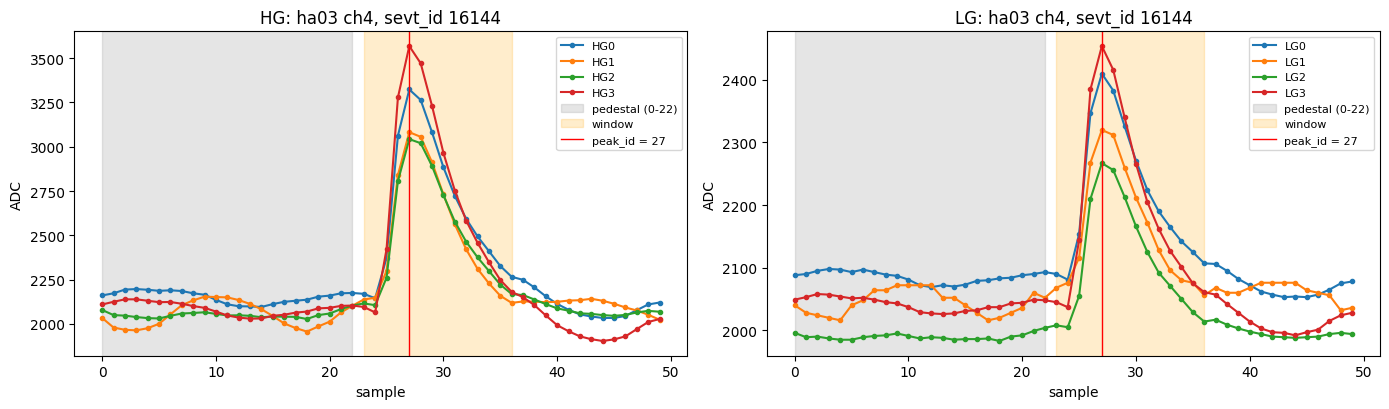

hg = 27772.9, lg = 7306.3, ped = [2153.4 2050.  2052.1 2088.2 2085.3 2044.2 1989.8 2042.5]


In [6]:
w = read_psa(OUT_WAVE, ["sevt_id", "board", "ch", "hg", "lg", "peak_id", "ped", "wave_sum", "satu_h", "satu_l", "adc"])
adc = w["adc"].reshape(-1, 50, 8).astype(float)
sel = np.where((w["board"] == 3) & ~w["satu_h"].astype(bool))[0]
k = sel[np.argsort(w["hg"][sel])[len(sel) // 2]]   # hg が真ん中のヒット
pk = w["peak_id"][k]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for g, name in enumerate(["HG", "LG"]):
    for c in range(4):
        ax[g].plot(adc[k, :, 4 * g + c], ".-", label=f"{name}{c}")
    ax[g].axvspan(0, 22, color="gray", alpha=0.2, label="pedestal (0-22)")
    ax[g].axvspan(max(0, pk - 4), min(49, pk + 9), color="orange", alpha=0.2, label="window")
    ax[g].axvline(pk, color="r", lw=1, label=f"peak_id = {pk}")
    ax[g].set_xlabel("sample"); ax[g].set_ylabel("ADC"); ax[g].set_title(f"{name}: ha03 ch{w['ch'][k]}, sevt_id {w['sevt_id'][k]}")
    ax[g].legend(fontsize=8)
fig.tight_layout(); plt.show()
print(f"hg = {w['hg'][k]:.1f}, lg = {w['lg'][k]:.1f}, ped = {np.round(w['ped'][k], 1)}")

## 4. 手で計算して比べる

上の表の手順を numpy で書き、ツリーの `hg`, `lg`, `peak_id` と比べます。全部のヒットで一致します
(`wave_sum` はツリーでは float なので、差は float の丸めの大きさ)。

In [7]:
ped = adc[:, :23, :].mean(axis=1)                      # [ヒット, 8]
sub = adc - ped[:, None, :]
peak = np.argmax(sub[:, :, 4:].sum(axis=2), axis=1)    # LG の和が最大のサンプル(同じ値なら最初)
ws, we = np.maximum(peak - 4, 0), np.minimum(peak + 9, 49)
r = np.arange(50)
inwin = (r[None, :] >= ws[:, None]) & (r[None, :] <= we[:, None])
# 台形: 窓の中の隣り合う 2 サンプルの平均を足す
pair = inwin[:, 1:] & inwin[:, :-1]
trap = (0.5 * (sub[:, 1:, :] + sub[:, :-1, :]) * pair[:, :, None]).sum(axis=1)   # [ヒット, 8]
hg, lg = trap[:, :4].sum(axis=1), trap[:, 4:].sum(axis=1)
print("peak_id   mismatches:", int((peak != w["peak_id"]).sum()), "/", len(peak))
print("hg  max |diff| / |hg| :", np.max(np.abs(hg - w["hg"]) / np.maximum(np.abs(w["hg"]), 1)))
print("lg  max |diff| / |lg| :", np.max(np.abs(lg - w["lg"]) / np.maximum(np.abs(w["lg"]), 1)))

peak_id   mismatches: 0 / 58652
hg  max |diff| / |hg| : 0.0
lg  max |diff| / |lg| : 0.0


## 5. ピークの位置 `peak_id`

多くのヒットは、ピークがトリガーの時刻(27 サンプル目前後)にあります。
HA_cal ではトリガーを全ボードで共有するので、あるボードは**ほかのボードのトリガーでも**波形を記録します。
そのとき、そのボードにたまたま来ていた時刻のずれた信号が入り、ピークが窓の中のどこかに出ます(下の図の平らな部分)。
こうした信号は積分の窓が波形の端で切れて `hg` が小さく出るので、位置やエネルギーの較正では、ピークがトリガーの時刻のヒットだけを使います
(`scripts/calib/` のスクリプトは、範囲を `temp_spectra.py` と同じ方法でデータから決める)。

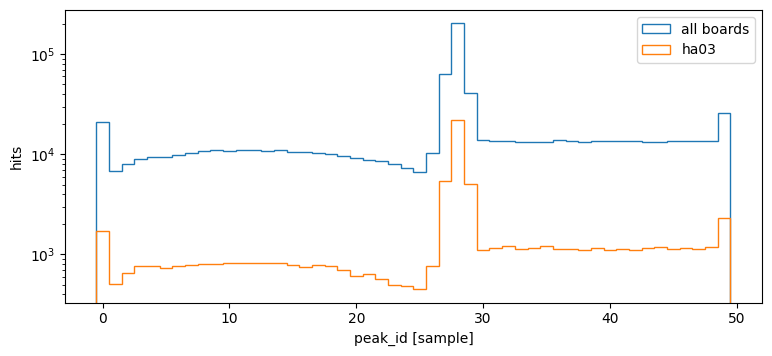

In [8]:
t = read_psa(OUT, ["board", "ch", "hg", "lg", "peak_id", "satu_h", "satu_l", "temp_mean", "time"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(t["peak_id"], bins=np.arange(-0.5, 50.5), log=True, histtype="step", label="all boards")
ax.hist(t["peak_id"][t["board"] == 3], bins=np.arange(-0.5, 50.5), histtype="step", label="ha03")
ax.set_xlabel("peak_id [sample]"); ax.set_ylabel("hits"); ax.legend()
plt.show()

## 6. スペクトル

`PSA_CalcFADC/HG_haNN`, `LG_haNN` は、ボードごとの `hg`, `lg` × ch のヒストグラムです(`save_spectra: true`)。
ha03 の 6 ch を描きます。この段階ではピクセルごとのゲインの違いが混ざっているので、ピークはなまっています
(ピクセルごとのスペクトルは [5_PSA_Calibration](../5_PSA_Calibration/PSA_Calibration.ipynb) の `PixelHG_haNN`)。

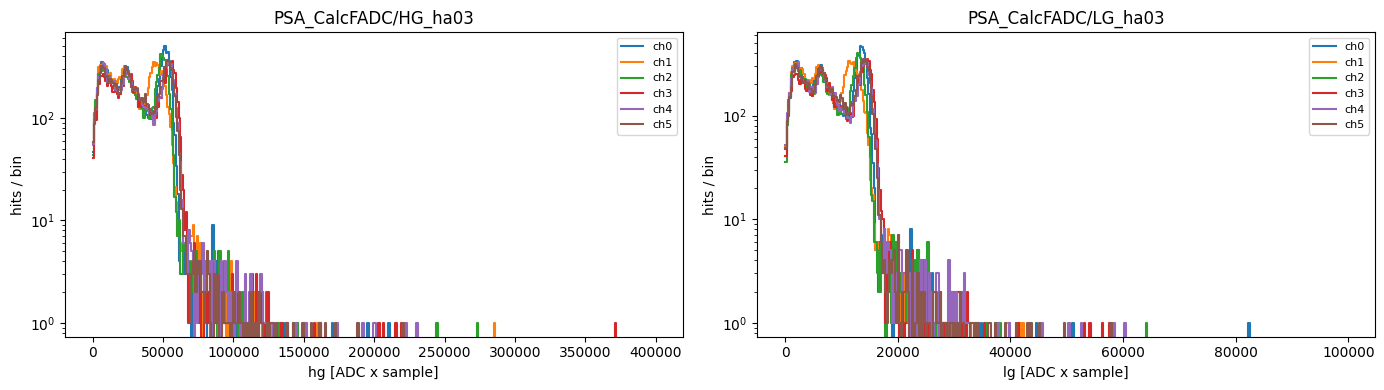

In [9]:
f = ROOT.TFile(str(OUT))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for g, name in enumerate(["HG", "LG"]):
    a, ex, ey = th2(f.Get(f"PSA_CalcFADC/{name}_ha03"))
    for c in range(6):
        ax[g].step(ex[:-1], a[:, c], where="post", label=f"ch{c}")
    ax[g].set_yscale("log"); ax[g].set_xlabel(f"{name.lower()} [ADC x sample]"); ax[g].set_ylabel("hits / bin")
    ax[g].set_title(f"PSA_CalcFADC/{name}_ha03"); ax[g].legend(fontsize=8)
fig.tight_layout(); plt.show()

HG と LG の関係です。HG はゲインが大きいので先に飽和します(`satu_h`、図の橙色)。大きい信号では LG を使う必要があります。

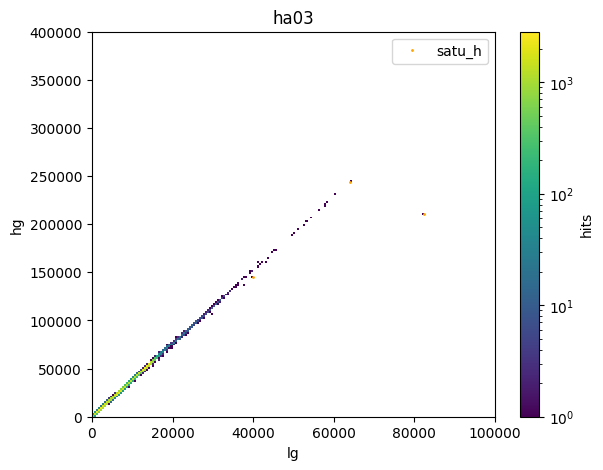

ha00: satu_h 0.03 %, satu_l 0.02 %
ha01: satu_h 0.02 %, satu_l 0.02 %
ha02: satu_h 0.02 %, satu_l 0.01 %
ha03: satu_h 0.03 %, satu_l 0.02 %
ha04: satu_h 0.03 %, satu_l 0.00 %
ha05: satu_h 0.02 %, satu_l 0.01 %
ha06: satu_h 0.02 %, satu_l 0.01 %
ha07: satu_h 0.01 %, satu_l 0.00 %
ha09: satu_h 0.02 %, satu_l 0.00 %
ha10: satu_h 0.01 %, satu_l 0.01 %
ha12: satu_h 0.02 %, satu_l 0.00 %
ha13: satu_h 0.02 %, satu_l 0.01 %
ha15: satu_h 0.02 %, satu_l 0.01 %
ha16: satu_h 0.03 %, satu_l 0.01 %


In [10]:
s = t["board"] == 3
sat = s & (t["satu_h"] == 1)
fig, ax = plt.subplots(figsize=(6.5, 5))
h = ax.hist2d(t["lg"][s], t["hg"][s], bins=200, range=[[0, 1e5], [0, 4e5]], norm=LogNorm(), cmap="viridis")
ax.plot(t["lg"][sat], t["hg"][sat], ".", ms=2, color="orange", label="satu_h")
fig.colorbar(h[3], ax=ax, label="hits"); ax.set_xlabel("lg"); ax.set_ylabel("hg"); ax.set_title("ha03"); ax.legend()
plt.show()
for b in np.unique(t["board"]):
    m = t["board"] == b
    print(f"ha{b:02d}: satu_h {100 * t['satu_h'][m].mean():.2f} %, satu_l {100 * t['satu_l'][m].mean():.2f} %")

## 7. 温度

`temp[6]` は温度センサー 6 個の値 [°C]、`temp_mean` はその平均です。ボードごとに時間変化を描きます。
MPPC のゲインは温度で大きく変わる(1 °C あたり約 −6%)ので、`PSA_Calibration` で温度ごとのゲインの表(`temp_gain_haNN.csv`)を使って `hg_corr` に直します。
`psa_param.csv` で温度の較正が仮の値のボード(`CAL_NOTE` が placeholder: ha09, ha10, ha12, ha13, ha15)は、値の確かさが劣ります。

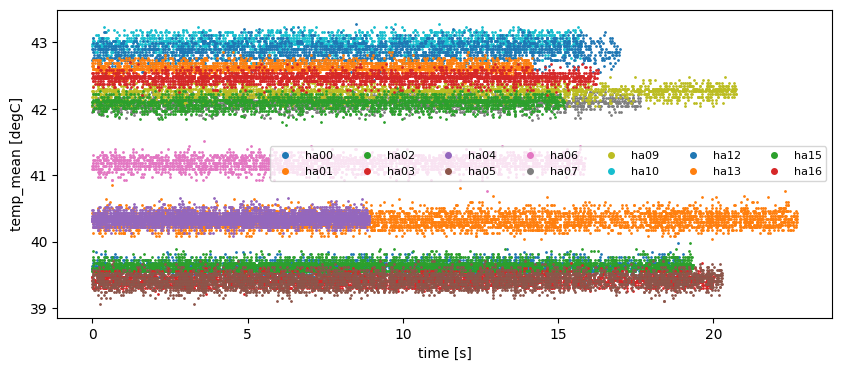

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for b in np.unique(t["board"]):
    m = t["board"] == b
    ax.plot(t["time"][m][::20], t["temp_mean"][m][::20], ".", ms=2, label=f"ha{b:02d}")
ax.set_xlabel("time [s]"); ax.set_ylabel("temp_mean [degC]"); ax.legend(ncol=7, fontsize=8, markerscale=4)
plt.show()

## 8. パラメータ

In [12]:
show_params("smile3_psa", "PSA_CalcFADC")

pedestal_samples = 23 [samples]
    ペデスタル(波形の最初のこのサンプル数の平均、信号ごと)
window_front = 4 [samples]
    積分の窓の始まり: ピーク(LG の和が最大のサンプル)のこのサンプル数前
window_back = 9 [samples]
    積分の窓の終わり: ピークのこのサンプル数後
fixed_window = false
    true: ピークによらず fixed_start から fixed_stop まで積分する(psa_decode.py の --constpeak)
fixed_start = 25 [sample index (0-49)]
    fixed_window のときの積分の始まり
fixed_stop = 41 [sample index (0-49)]
    fixed_window のときの積分の終わり
psa_param_file = "{repo}/calib/psa/psa_param.csv"
    温度センサーの較正(HA 列が ha<NN> の行の TL..BR _A, _B)。無いボードは psa_decode.py の既定値
save_spectra = true
    true: ボードごとの hg, lg スペクトル(HG_haNN, LG_haNN、ch ごと)を保存する
hg_max = 400000.0 [ADC x sample]
    hg スペクトルの上限
lg_max = 100000.0 [ADC x sample]
    lg スペクトルの上限
spec_bins = 400
    hg, lg スペクトルのビン数
